# 03 - Feature engineering & modeling - all five lenses

One notebook, five models, five different **targets**:

| Lens | Target | Problem type | Models |
|---|---|---|---|
| A | `Churn` 0/1 | binary classification | LogReg -> RandomForest -> HistGradientBoosting |
| B | (`tenure`, `Churn`) | survival / time-to-event | Kaplan-Meier, Cox PH, Weibull AFT |
| C | `conversion` given `treatment_group` | uplift (causal) | Solo/S, Two/T, ClassTransformation |
| D | - (unsupervised) | clustering | K-Means (Telco features; Retail RFM) |
| E | future purchases & spend | probabilistic regression | BG/NBD + Gamma-Gamma |

**The one leakage rule, applied everywhere:** split (or time-split) FIRST; fit every
transformer inside a Pipeline on training data only. Every fitted artifact is saved to
`models/` - notebook 04 analyzes them, notebook 05 serves them; nothing is retrained
downstream.

In [1]:
import sys
from pathlib import Path

# Make src/ importable whether Jupyter starts in the project root or in Code/
for candidate in (Path.cwd(), Path.cwd() / "Code", Path.cwd().parent):
    if (candidate / "phase_1").exists():
        sys.path.insert(0, str(candidate))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)

from phase_1.loader import load_telco, load_retail, load_megafon, save_processed
from phase_1 import eda, features, models
eda.set_style()

## Lens A - churn classification

### A.1 Feature engineering - each feature is a hypothesis

- `tenure_bucket` - EDA showed risk is front-loaded; give the model the lifecycle stage
- `services_count` - entanglement: more services, harder to leave
- `avg_monthly_spend` - spend intensity robust to the tenure-0 newcomers
- `is_month_to_month` - THE contract effect isolated as a flag
- `has_no_support_services` - the "fiber with no safety net" profile from EDA

In [2]:
telco = load_telco()
eng = features.engineer_telco(telco)
eng[["tenure", "tenure_bucket", "services_count", "avg_monthly_spend",
     "is_month_to_month", "has_no_support_services"]].head()

,tenure,tenure_bucket,services_count,avg_monthly_spend,is_month_to_month,has_no_support_services
0,1,0-12,1,29.850000,1,1
1,34,25-48,3,55.573529,0,0
2,2,0-12,3,54.075000,1,0
3,45,25-48,3,40.905556,0,0
4,2,0-12,1,75.825000,1,1


### A.2 Split first, then build the preprocessing

80/20 stratified. The `ColumnTransformer` (scale numerics, one-hot categoricals) is
*not fitted here* - it is fitted inside each model's Pipeline, on training folds only.
That is what makes cross-validation honest.

In [3]:
X_train, X_test, y_train, y_test = features.split_telco(eng)
numeric, categorical = features.telco_feature_lists(eng)
pre = features.make_preprocessor(numeric, categorical)
print(f"train {X_train.shape} / test {X_test.shape}")
print(f"{len(numeric)} numeric: {numeric}")
print(f"{len(categorical)} categorical: {categorical}")

train (5634, 24) / test (1409, 24)
7 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'services_count', 'avg_monthly_spend', 'is_month_to_month', 'has_no_support_services']
17 categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_bucket']


### A.3 Baseline -> challengers, 5-fold CV

Logistic regression is the bar: interpretable and hard to beat on this dataset.
`class_weight="balanced"` handles the 73/27 imbalance without synthetic resampling
(tested SMOTE off-line: no gain here, one extra dependency - class weights win).

In [4]:
zoo, cv_table = models.train_churn_models(X_train, y_train, pre)
cv_table

,model,cv_roc_auc_mean,cv_roc_auc_std
0,random_forest,0.846591,0.009865
1,logistic_regression,0.845706,0.011839
2,hist_gradient_boosting,0.835843,0.008622


### A.4 Time-boxed tuning of the boosted model

25 random-search draws, deliberately. This dataset plateaus around 0.85 ROC-AUC -
past that you are tuning noise. The interesting work is in thresholds (notebook 04),
not hyperparameters.

In [5]:
tuned, search_results = models.tune_hgb(X_train, y_train, pre, n_iter=25)
search_results.head()

,params,mean_test_score,std_test_score
0,"{'clf__min_samples_leaf': 10, 'clf__max_leaf_n...",0.846360,0.010634
1,"{'clf__min_samples_leaf': 20, 'clf__max_leaf_n...",0.846018,0.010640
2,"{'clf__min_samples_leaf': 10, 'clf__max_leaf_n...",0.845896,0.010864
3,"{'clf__min_samples_leaf': 40, 'clf__max_leaf_n...",0.845092,0.011152
4,"{'clf__min_samples_leaf': 40, 'clf__max_leaf_n...",0.844749,0.010789


In [6]:
from sklearn.metrics import roc_auc_score

test_scores = {name: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
               for name, m in {**zoo, "tuned_hgb": tuned}.items()}
pd.Series(test_scores, name="test_roc_auc").sort_values(ascending=False).round(4)

tuned_hgb                 0.8448
random_forest             0.8429
logistic_regression       0.8426
hist_gradient_boosting    0.8346
Name: test_roc_auc, dtype: float64

### A.5 Save the artifacts

Bundles carry the exact training feature list - scoring code reindexes to it, so a
column-order change in someone's CSV can never silently corrupt predictions.

In [7]:
feat_list = list(X_train.columns)
models.save_model({"pipeline": tuned, "features": feat_list}, "churn_pipeline")
models.save_model({"models": zoo, "features": feat_list}, "churn_zoo")
save_processed(X_train.assign(Churn=y_train), "telco_train")
save_processed(X_test.assign(Churn=y_test), "telco_test")
models.update_metrics("lens_A", {
    "cv": cv_table.to_dict("records"),
    "test_roc_auc": test_scores,
    "n_train": len(X_train), "n_test": len(X_test),
})
print("saved: churn_pipeline, churn_zoo, telco_train/test parquet")

saved: churn_pipeline, churn_zoo, telco_train/test parquet


## Lens B - survival analysis (when do they leave?)

Same customers, different question. Key concept: **censoring** - the 73% who haven't
churned are not "no events", they are "no event *yet*"; survival methods use that
partial information correctly, classification cannot.

`encode_for_survival` drops `TotalCharges` deliberately: it ~ tenure x MonthlyCharges,
i.e. it *is* the duration - a survival covariate must not contain the outcome.

concordance: {'cox': 0.8579957996878651, 'weibull_aft': 0.8648016383150468}


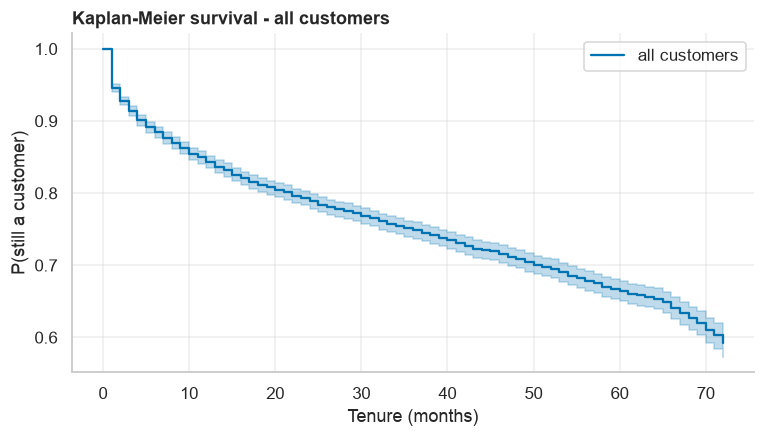

In [8]:
sdf = features.encode_for_survival(telco)
surv = models.train_survival(sdf)
print("concordance:", surv["c_index"])
ax = surv["km"].plot(figsize=(8, 4))
ax.set(title="Kaplan-Meier survival - all customers",
       xlabel="Tenure (months)", ylabel="P(still a customer)")
plt.show()

In [9]:
surv["cox"].summary[["coef", "exp(coef)", "p"]].sort_values(
    "exp(coef)", ascending=False).head(8)

,coef,exp(coef),p
covariate,,,
PaymentMethod_Electronic check,0.460220,1.584422,9.197422e-23
InternetService_Fiber optic,0.368330,1.445319,5.097552e-12
PaymentMethod_Mailed check,0.249149,1.282934,2.111900e-05
PaperlessBilling_Yes,0.204471,1.226876,5.541765e-06
SeniorCitizen_Yes,0.022094,1.022340,6.527101e-01
MonthlyCharges,0.002422,1.002424,2.662126e-02
gender_Male,-0.044428,0.956544,2.601921e-01
PhoneService_Yes,-0.070720,0.931723,3.570157e-01


Read `exp(coef)` as a hazard multiplier (>1 = leaves sooner). The usual suspects
top the list - month-to-month, fiber, electronic check - now with *time* attached.

Save the Cox bundle with its covariate list (notebook 05 scores new data against it),
plus the expected-remaining-tenure it produces (the B->E bridge).

In [10]:
covariates = [c for c in sdf.columns if c not in ("tenure", "Churn")]
models.save_model({"model": surv["cox"], "columns": covariates}, "cox_bundle")
remaining = models.expected_remaining_tenure(surv["cox"], sdf)
print(remaining.describe().round(1))
models.update_metrics("lens_B", surv["c_index"])

count    7043.0
mean       18.9
std        16.4
min         0.0
25%         2.0
50%        16.9
75%        31.3
max        70.1
Name: expected_remaining_tenure, dtype: float64


## Lens C - uplift on MegaFon (who is *persuadable*?)

Classification asks "will they convert?"; uplift asks "**does the campaign change**
whether they convert?" - four customer types (sure things, lost causes, persuadables,
sleeping dogs), and only persuadables deserve budget.

Three meta-learners, judged on Qini in notebook 04. `treatment_group` is passed
separately to `.fit(X, y, treatment)` - it is the causal switch, never a feature.
 ~600K rows x several fits: expect a few minutes.

In [11]:
mega = load_megafon()
X, t, y = features.megafon_xty(mega)
X_tr, X_val, t_tr, t_val, y_tr, y_val = features.split_megafon(X, t, y)
uplift_zoo = models.train_uplift(X_tr, y_tr, t_tr)
print("fitted:", list(uplift_zoo))

fitted: ['solo_model', 'two_models', 'class_transformation']


In [12]:
from phase_1.evaluation import qini_report

qini = qini_report(uplift_zoo, X_val, y_val, t_val)
qini

/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtyp

,model,qini_auc,uplift@10%,uplift@20%
0,two_models,0.2390,0.4407,0.2816
1,solo_model,0.2314,0.4193,0.2684
2,class_transformation,0.0334,0.1510,0.0983


In [13]:
best_name = qini.iloc[0]["model"]
models.save_model({"model": uplift_zoo[best_name], "features": list(X.columns),
                   "name": best_name}, "uplift_model")
models.save_model({"models": uplift_zoo, "features": list(X.columns)}, "uplift_zoo")
save_processed(X_val.assign(treatment=t_val.values, conversion=y_val.values),
               "megafon_val")
models.update_metrics("lens_C", qini.to_dict("records"))
print(f"saved uplift_model ({best_name}) + megafon_val parquet")

saved uplift_model (two_models) + megafon_val parquet


## Lens D - segmentation

### D.1 Telco: K-Means on the engineered features

Scaling happens inside the pipeline (K-Means is distance-based; unscaled dollars would
dominate one-hot flags). k chosen where silhouette peaks & the elbow bends - then the
real test: do the clusters read as *people* and separate churn rates?

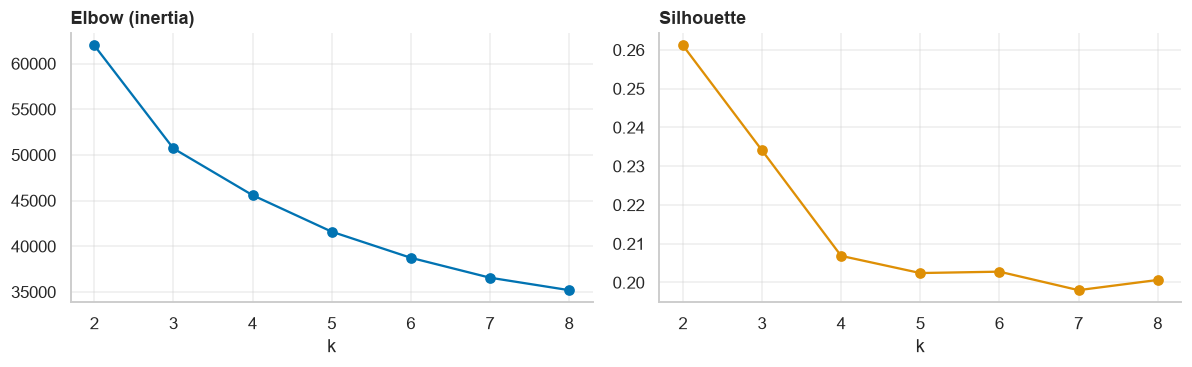

,k,inertia,silhouette
0,2,61993.715447,0.261171
1,3,50706.024700,0.234084
2,4,45592.734444,0.206862
3,5,41598.143041,0.202432
4,6,38738.073351,0.202789
5,7,36559.658664,0.198019
6,8,35194.313070,0.200650


In [14]:
X_all = eng.drop(columns=["customerID", "Churn"])
pre_d = features.make_preprocessor(*features.telco_feature_lists(eng))
scan = models.kmeans_scan(pre_d.fit_transform(X_all), ks=range(2, 9))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(scan["k"], scan["inertia"], marker="o", color=eda.PALETTE[0])
ax1.set(title="Elbow (inertia)", xlabel="k")
ax2.plot(scan["k"], scan["silhouette"], marker="o", color=eda.PALETTE[1])
ax2.set(title="Silhouette", xlabel="k")
plt.tight_layout(); plt.show()
scan

In [15]:
K_TELCO = int(scan.loc[scan["silhouette"].idxmax(), "k"])
print(f"chosen k = {K_TELCO} (silhouette peak; overridable after eyeballing profiles)")
km_pipe = models.fit_kmeans_pipeline(X_all, features.make_preprocessor(
    *features.telco_feature_lists(eng)), K_TELCO)
models.save_model({"pipeline": km_pipe, "features": list(X_all.columns)}, "kmeans_telco")
labels = km_pipe.predict(X_all)
pd.Series(labels).value_counts().sort_index().rename("cluster size")

chosen k = 2 (silhouette peak; overridable after eyeballing profiles)


0    2762
1    4281
Name: cluster size, dtype: int64

### D.2 Retail: K-Means on log-RFM

Same method, different space: each customer as (Recency, Frequency, Monetary),
log1p-transformed first (EDA showed the whale skew - without the log, one whale
would be its own cluster and everyone else a blob).

In [16]:
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from phase_1 import config

retail = load_retail()
rfm = features.rfm_table(retail)
RFM_COLS = ["Recency", "Frequency", "Monetary"]
rfm_pipe = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, n_init=10, random_state=config.RANDOM_SEED)),
]).fit(rfm[RFM_COLS])
models.save_model({"pipeline": rfm_pipe, "features": RFM_COLS}, "rfm_kmeans")
rfm["cluster"] = rfm_pipe.predict(rfm[RFM_COLS])
rfm.groupby("cluster")[RFM_COLS].mean().round(1).join(
    rfm["cluster"].value_counts().rename("n"))

,Recency,Frequency,Monetary,n
cluster,,,,
0,394.9,1.4,317.1,1973
1,28.3,3.1,857.5,1250
2,27.7,19.3,10731.2,1196
3,230.1,5.1,1948.5,1459


## Lens E - CLV (BG/NBD + Gamma-Gamma)

The **falsifiability step first**: split time into an 18-month calibration window and
a ~6-month holdout. Fit on calibration only; notebook 04 checks predictions against
what customers actually did in the holdout. A CLV model that skips this is astrology.

Then fit production models on the full history and save.

In [17]:
cal = features.clv_calibration_holdout(retail, holdout_days=180)
from lifetimes import BetaGeoFitter
bgf_cal = BetaGeoFitter(penalizer_coef=0.001)
bgf_cal.fit(cal["frequency_cal"], cal["recency_cal"], cal["T_cal"])
models.save_model({"bgf_cal": bgf_cal}, "clv_calibration")
save_processed(cal.reset_index(), "clv_cal_holdout")
print(bgf_cal)

<lifetimes.BetaGeoFitter: fitted with 4977 subjects, a: 0.09, alpha: 65.42, b: 1.30, r: 0.68>


In [18]:
summary = features.clv_summary(retail)
clv_models = models.train_clv(summary)      # prints an assumption warning if strained
clv = models.clv_per_customer(clv_models, summary)
models.save_model(clv_models, "clv_models")
save_processed(summary.join(clv).reset_index(), "clv_summary")
models.update_metrics("lens_E", {
    "freq_monetary_corr": clv_models["freq_monetary_corr"],
    "customers": len(summary), "mean_clv_12m": float(clv.mean()),
})
clv.describe().round(2)

count      5878.00
mean       1394.36
std        7632.09
min           0.00
25%           0.00
50%         362.46
75%        1198.85
max      323584.77
Name: clv, dtype: float64

## Promoted to `phase_1/`  - and the artifact inventory

Functions -> `phase_1/preprocessing/features.py` (engineering, splits, RFM, CLV data prep) and
`phase_1/modeling/models.py` (every trainer + save/load + metrics).

Artifacts now in `models/` - the complete dependency of notebooks 04/05 and the app:

In [19]:
from phase_1 import config
sorted(p.name for p in config.MODEL_DIR.glob("*.joblib"))

['churn_pipeline.joblib',
 'churn_zoo.joblib',
 'clv_calibration.joblib',
 'clv_models.joblib',
 'cox_bundle.joblib',
 'kmeans_telco.joblib',
 'rfm_kmeans.joblib',
 'uplift_model.joblib',
 'uplift_zoo.joblib']

**Next:** `04_result_analysis.ipynb` - nothing gets retrained; everything gets
questioned.